<a href="https://colab.research.google.com/github/Izaias02/-ATV04PW2/blob/main/3_gold_saude.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# 1. CARREGANDO OS PACOTES PARA A CAMADA GOLD
# ============================================================
library(googledrive)
library(readr)
library(dplyr)
library(ggplot2) # Biblioteca para gerar o gráfico do Boxplot

cat("✅ Pacotes carregados e prontos para a análise estatística do SBC!\n")



Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




✅ Pacotes carregados e prontos para a análise estatística do SBC!


In [ ]:
# ============================================================
# 2. IDENTIFICAÇÃO E ENTRADA DA BASE TRATADA (SILVER -> GOLD)
# ============================================================

# Define as variáveis do ambiente de forma independente
nome_pasta_aluno <- "Izaias"
pasta_aula       <- "Aula 6 - 31/08/2026"

cat("🔍 Buscando o arquivo limpo 'hospitais_leitos_sp_2025_silver.csv' no Google Drive...\n")

# Localiza o arquivo de forma global pelo nome, eliminando erros de caminhos textuais
arquivo_silver_id <- drive_find(pattern = "hospitais_leitos_sp_2025_silver.csv", n_max = 1)

if (nrow(arquivo_silver_id) > 0) {
  cat("✅ Arquivo Silver localizado! ID de Rede:", arquivo_silver_id$id, "\n")

  # Baixa o arquivo purificado da Silver para o ambiente da Gold
  drive_download(
    file = as_id(arquivo_silver_id$id),
    path = "/content/hospitais_leitos_sp_2025_silver.csv",
    overwrite = TRUE
  )

  # Cria o dataframe oficial da Gold
  df_saude_gold <- read_csv(
    "/content/hospitais_leitos_sp_2025_silver.csv",
    locale = locale(encoding = "UTF-8"),
    show_col_types = FALSE
  )

  cat("\n🎉 SUCESSO! Base carregada na Camada Gold com", nrow(df_saude_gold), "linhas únicas.\n")

} else {
  cat("❌ ERRO EXTRAORDINÁRIO: O arquivo limpo da Silver não foi encontrado no seu Drive.\n")
}


🔍 Buscando o arquivo limpo 'hospitais_leitos_sp_2025_silver.csv' no Google Drive...


Is it OK to cache OAuth access credentials in the folder ~/.cache/gargle
between R sessions?
1: Yes
2: No


Selection: 1


Please point your browser to the following url: 

https://accounts.google.com/o/oauth2/v2/auth?client_id=603366585132-frjlouoa3s2ono25d2l9ukvhlsrlnr7k.apps.googleusercontent.com&scope=https%3A%2F%2Fwww.googleapis.com%2Fauth%2Fdrive%20https%3A%2F%2Fwww.googleapis.com%2Fauth%2Fuserinfo.email&redirect_uri=https%3A%2F%2Fwww.tidyverse.org%2Fgoogle-callback%2F&response_type=code&state=36d1abfbe426d2c0b17f6ddea786983f&access_type=offline&prompt=consent



Enter authorization code: eyJjb2RlIjoiNC8wQVRzTVpxRHlXQ1Vhanp3LTZkQktVUWVzNkNJRWEtdklMMFRSdHNhQ3JIQlI0cEJZUDlXMlhIVGtxT0dXeHFzaXJzTUZOUSIsInN0YXRlIjoiMzZkMWFiZmJlNDI2ZDJjMGIxN2Y2ZGRlYTc4Njk4M2YifQ==
✅ Arquivo Silver localizado! ID de Rede: 1H4SVdfQPVtgVlUjgWruSeD1IeYQ6HYnJ 


File downloaded:

• hospitais_leitos_sp_2025_silver.csv <id: 1H4SVdfQPVtgVlUjgWruSeD1IeYQ6HYnJ>

Saved locally as:

• /content/hospitais_leitos_sp_2025_silver.csv




🎉 SUCESSO! Base carregada na Camada Gold com 1019 linhas únicas.


In [ ]:
# ============================================================
# 3. CÁLCULO DOS PARÂMETROS ESTATÍSTICOS (BASE GOLD)
# ============================================================

# Calculando as métricas de leitos na base purificada
materia_media     <- mean(df_saude_gold$leitos_existentes, na.rm = TRUE)
materia_mediana   <- median(df_saude_gold$leitos_existentes, na.rm = TRUE)
materia_variancia <- var(df_saude_gold$leitos_existentes, na.rm = TRUE)
materia_desvio    <- sd(df_saude_gold$leitos_existentes, na.rm = TRUE)

# Calculando os Quartis para a anatomia do Boxplot
q1   <- quantile(df_saude_gold$leitos_existentes, 0.25, na.rm = TRUE)
q3   <- quantile(df_saude_gold$leitos_existentes, 0.75, na.rm = TRUE)
iqr  <- q3 - q1
cerca_superior <- q3 + (1.5 * iqr)

# Exibindo os resultados na tela do Colab para auditoria
cat("=== 📊 PARÂMETROS DA BASE DE CONHECIMENTO (GOLD) ===\n")
cat("Média de Leitos por Hospital: ", round(materia_media, 2), "\n")
cat("Mediana de Leitos (Centro Real): ", materia_mediana, "\n")
cat("Variância dos Dados: ", round(materia_variancia, 2), "\n")
cat("Desvio Padrão (Afastamento): ", round(materia_desvio, 2), "\n")
cat("--------------------------------------------------\n")
cat("Primeiro Quartil (Q1): ", q1, "\n")
cat("Terceiro Quartil (Q3): ", q3, "\n")
cat("Intervalo Interquartil (IQR): ", iqr, "\n")
cat("Linha de Corte para Outlier (Cerca Superior): ", cerca_superior, "\n")


=== 📊 PARÂMETROS DA BASE DE CONHECIMENTO (GOLD) ===
Média de Leitos por Hospital:  107.16 
Mediana de Leitos (Centro Real):  68 
Variância dos Dados:  16678.55 
Desvio Padrão (Afastamento):  129.15 
--------------------------------------------------
Primeiro Quartil (Q1):  31 
Terceiro Quartil (Q3):  139.5 
Intervalo Interquartil (IQR):  108.5 
Linha de Corte para Outlier (Cerca Superior):  302.25 


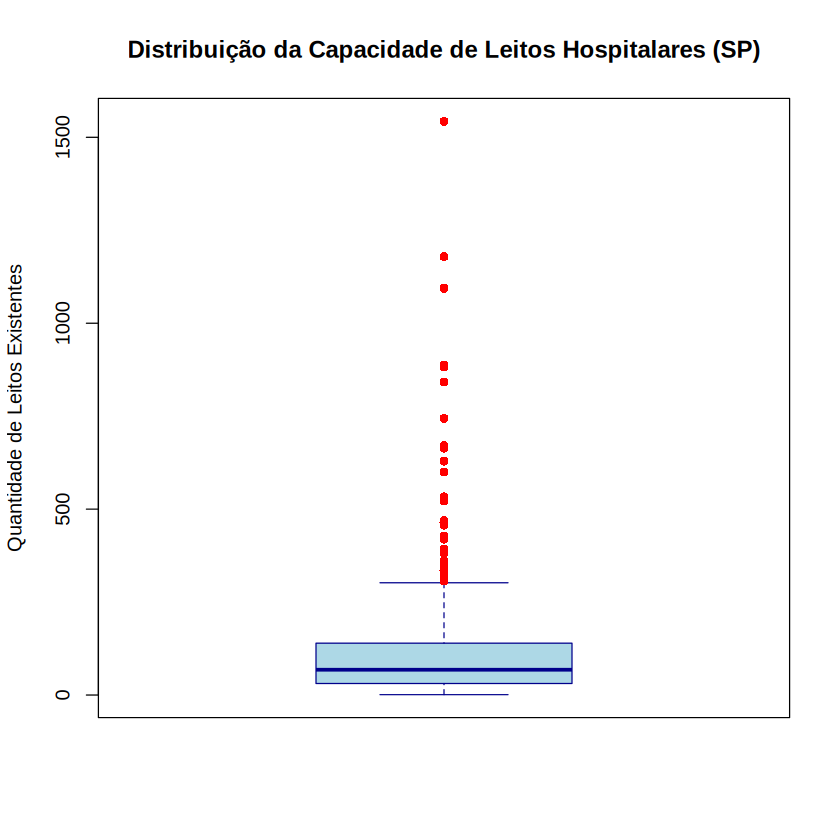

In [ ]:
# ============================================================
# 4. CONSTRUÇÃO VISUAL DO BOXPLOT (SBC SAÚDE)
# ============================================================

boxplot(df_saude_gold$leitos_existentes,
        main = "Distribuição da Capacidade de Leitos Hospitalares (SP)",
        ylab = "Quantidade de Leitos Existentes",
        col = "lightblue",
        border = "darkblue",
        outcol = "red", # Destaca os outliers em vermelho
        outpch = 16)


In [ ]:
# ============================================================
# 5.1. ENGENHARIA DE INDICADORES AVANÇADOS PARA O SBC (SLIDE ITEM 5)
# ============================================================

df_municipios_analise <- df_saude_gold |>
  group_by(municipio) |>
  summarise(
    total_estabelecimentos   = n(),
    total_leitos_geral       = sum(leitos_existentes, na.rm = TRUE),
    total_leitos_sus         = sum(leitos_sus, na.rm = TRUE),
    total_uti_geral          = sum(uti_total_existente, na.rm = TRUE),
    total_uti_sus            = sum(uti_total_sus, na.rm = TRUE),

    # Indicador 1: Percentual de leitos que NÃO atendem pelo SUS (Privatização da Rede)
    pct_leitos_privados      = ((total_leitos_geral - total_leitos_sus) / total_leitos_geral) * 100,

    # Indicador 2: Razão de UTIs SUS sobre o total de UTIs instaladas
    proporcao_uti_sus        = (total_uti_sus / total_uti_geral) * 100
  ) |>
  # Filtro de relevância: cidades com infraestrutura hospitalar mínima ativa
  filter(total_leitos_geral > 0)

# Substituindo os valores "Not a Number" (NaN) que ocorrem onde não há nenhuma UTI cadastrada
df_municipios_analise[is.na(df_municipios_analise)] <- 0

# Exibindo o ranking dos 5 municípios com maior dependência da rede privada (Maior pct_leitos_privados)
cat("=== 🚨 TOP 5 MUNICÍPIOS COM MENOR DISPONIBILIDADE RELATIVA DE LEITOS SUS ===\n")
df_municipios_analise |>
  arrange(desc(pct_leitos_privados)) |>
  select(municipio, total_leitos_geral, total_leitos_sus, pct_leitos_privados) |>
  head(5)


=== 🚨 TOP 5 MUNICÍPIOS COM MENOR DISPONIBILIDADE RELATIVA DE LEITOS SUS ===


municipio,total_leitos_geral,total_leitos_sus,pct_leitos_privados
<chr>,<dbl>,<dbl>,<dbl>
ARACOIABA DA SERRA,45,0,100
CEDRAL,60,0,100
SANTA LUCIA,8,0,100
TREMEMBE,12,0,100
VARGEM GRANDE PAULISTA,40,0,100


Warning message in xy.coords(x, y, xlabel, ylabel, log):
“5 y values <= 0 omitted from logarithmic plot”
Warning message in int_abline(a = a, b = b, h = h, v = v, untf = untf, ...):
“"linetype" is not a graphical parameter”


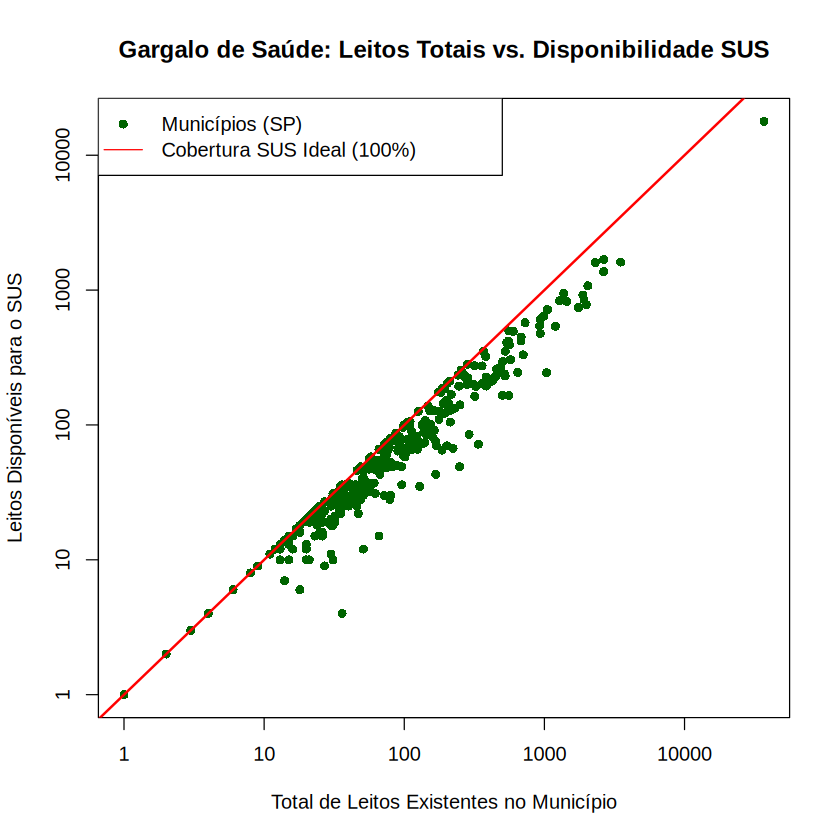

In [ ]:
# ============================================================
# 5.2. GRÁFICO DE DISPERSÃO: ASSIMETRIA DE OFERTA PÚBLICA
# ============================================================

plot(df_municipios_analise$total_leitos_geral, df_municipios_analise$total_leitos_sus,
     main = "Gargalo de Saúde: Leitos Totais vs. Disponibilidade SUS",
     xlab = "Total de Leitos Existentes no Município",
     ylab = "Leitos Disponíveis para o SUS",
     col = "darkgreen", pch = 16, log = "xy") # Escala logarítmica para acomodar os 20.000 registros

# Adiciona uma linha de igualdade perfeita (Se o SUS cobrisse 100% dos leitos do estado)
abline(a = 0, b = 1, col = "red", linetype = "dashed", lwd = 2)
legend("topleft", legend = c("Municípios (SP)", "Cobertura SUS Ideal (100%)"), col = c("darkgreen", "red"), pch = c(16, NA), lty = c(NA, 1))


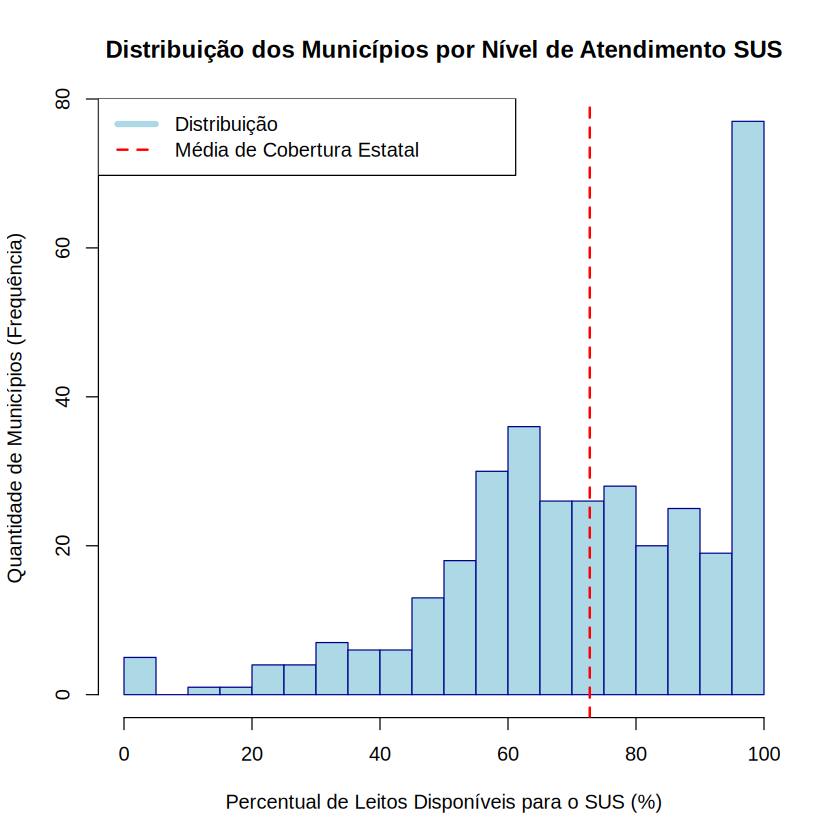

In [ ]:
# ============================================================
# 5.3. GRAVAÇÃO DE NOVO GRÁFICO: HISTOGRAMA DE DEPENDÊNCIA
# ============================================================

# Calcula o percentual de leitos SUS reais por município
df_municipios_analise$pct_leitos_sus <- 100 - df_municipios_analise$pct_leitos_privados

# Plota o histograma
hist(df_municipios_analise$pct_leitos_sus,
     breaks = 20,
     main = "Distribuição dos Municípios por Nível de Atendimento SUS",
     xlab = "Percentual de Leitos Disponíveis para o SUS (%)",
     ylab = "Quantidade de Municípios (Frequência)",
     col = "lightblue",
     border = "darkblue")

# Adiciona uma linha média para o relatório
abline(v = mean(df_municipios_analise$pct_leitos_sus), col = "red", lwd = 2, lty = 2)
legend("topleft", legend = c("Distribuição", "Média de Cobertura Estatal"), col = c("lightblue", "red"), lty = c(1, 2), lwd = c(5, 2))
